# Модель платформи ЦД верстата з ЧПК — SysML v2

ЛР 1, варіант 3. Мова: **SysML v2** (Pilot Implementation, ядро Jupyter `sysml`).
Пакети: `Requirements` (вимоги за доменами ISO 23247), `Structure` (блоки й порти), `Behavior` (діяльність і стани), `Verification` (перевірки, verify), `Traceability` (satisfy).

In [1]:
package CncMachineTwin {
    doc /* Платформа цифрового двійника вертикально-фрезерного обробного центру з ЧПК.
         * ЛР 1, варіант 3. Мова моделі: SysML v2 (Pilot Implementation).
         * Склад блоків відповідає docs/iso23247-mapping.md і docs/diagrams/components.mmd. */

    private import ScalarValues::*;

    // =====================================================================
    // 1. ВИМОГИ — згруповано за доменами ISO 23247
    // =====================================================================
    package Requirements {

        package DCE_DataCollection {
            doc /* DCE: збирання даних */
            requirement <'FR-01'> collectSignals {
                doc /* Платформа збирає 13 сигналів реєстру з ЧПК (OPC UA) та модуля DAQ
                     * із частотами реєстру, а також ім'я активної NC-програми й лічильник деталей;
                     * для кожного відліку зберігається часова мітка джерела. */
                attribute signalCount : Integer = 13;
            }
            requirement <'FR-02'> vibrationFeatures {
                doc /* Граничний шлюз обчислює з сирої вібрації S01 вісім ознак у суміжних вікнах
                     * 512 відліків із кроком близько 102 мс. */
                attribute featureCount : Integer = 8;
            }
            requirement <'NFR-05'> noDataLoss {
                doc /* За розриву зв'язку шлюз-платформа до 15 хв втрата ознак вібрації та повільних
                     * сигналів S02-S13 0 %; для сирих блоків вібрації доставка не гарантується. */
                attribute outageMinutes : Real = 15.0;
                attribute lossPercent : Real;
                require constraint { lossPercent == 0.0 }
            }
        }

        package DTE_ApplicationsAndServices {
            doc /* DTE: застосунки та служби */
            requirement <'FR-04'> chatterAndOverload {
                doc /* Виявлення автоколивань і перевантаження шпинделя (S02 > 120 % довше 0,5 с)
                     * зі сповіщенням оператора та рекомендацією зменшити оберти або подачу. */
            }
            requirement <'FR-05'> toolWear {
                doc /* Оцінка зносу інструмента й залишкового ресурсу; попередження при 80 % ресурсу. */
                attribute warnThreshold : Real = 0.8;
            }
            requirement <'FR-08'> shiftReport {
                doc /* Звіт за зміну (час різання, простої, аварії, завантаження) у PDF/CSV і передача в MES. */
            }
        }

        package DTE_OperationAndManagement {
            doc /* DTE: функціонування та керування */
            requirement <'FR-06'> history {
                doc /* Зберігання історії, запити за інтервалом часу, тренди, вивантаження CSV. */
            }
            requirement <'NFR-01'> syncLatency {
                doc /* Затримка синхронізації стану (мітка джерела -> стан у Twin API) <= 200 мс для 95 % оновлень. */
                attribute p95Ms : Real;
                require constraint { p95Ms <= 200.0 }
            }
            requirement <'NFR-03'> scalability {
                doc /* Зростання з 1 до 10 верстатів (13 -> 130 сигналів) збільшує p95 синхронізації не більш ніж на 30 %. */
                attribute growth : Real;
                require constraint { growth <= 0.30 }
            }
            requirement <'NFR-04'> retention {
                doc /* Ознаки й S02-S08, S11-S13: повна роздільність 30 діб, похвилинні агрегати 12 міс.;
                     * S09, S10: повна роздільність 12 міс.; сира вібрація 7 діб; сховище <= 100 ГБ на верстат на рік. */
                attribute storageGbPerYear : Real;
                require constraint { storageGbPerYear <= 100.0 }
            }
        }

        package UE_User {
            doc /* UE: користувач */
            requirement <'FR-03'> liveView {
                doc /* Веб-панель показує режим, програму, інструмент, положення осей, оберти, подачу,
                     * навантаження шпинделя та ознаки вібрації в реальному часі. */
            }
            requirement <'NFR-02'> endToEndLatency {
                doc /* Наскрізна затримка «датчик - подання» <= 500 мс для 95 % оновлень. */
                attribute p95Ms : Real;
                require constraint { p95Ms <= 500.0 }
            }
        }

        package CrossCutting {
            doc /* Наскрізна сутність: якість даних, захищеність */
            requirement <'FR-07'> dataQuality {
                doc /* Перевірка відліку (діапазон, монотонність міток, пропуски, «завмерле» значення)
                     * з позначкою якості good / uncertain / bad. */
            }
            requirement <'NFR-06'> security {
                doc /* Усі канали зашифровано (OPC UA SignAndEncrypt, MQTT/TLS, HTTPS/WSS), доступ за ролями,
                     * 0 відкритих незашифрованих портів. */
                attribute openPlainPorts : Integer;
                require constraint { openPlainPorts == 0 }
            }
        }
    }

    // =====================================================================
    // 2. СТРУКТУРА — блоки зі стовпця «Блок SysML» таблиці відповідності ISO 23247
    // =====================================================================
    package Structure {

        // ---- Предмети потоків ----
        item def TelemetrySample {
            doc /* Відлік сигналу або ознаки в уніфікованій схемі InfoModel */
            attribute signalId : String;
            attribute value : Real;
            attribute sourceTimestamp : Real;
            attribute quality : String;
        }
        item def TwinState {
            doc /* Поточний стан двійника верстата */
            attribute mode : String;
            attribute toolNumber : Integer;
        }
        item def Alert {
            doc /* Подія: автоколивання, перевантаження, знос */
            attribute kind : String;
            attribute severity : Integer;
        }

        // ---- Порти ----
        port def TelemetryFlow { out item sample : TelemetrySample; }
        port def StateFlow     { out item twinState : TwinState; }
        port def AlertFlow     { out item alert : Alert; }

        // ---- OME: фізичний об'єкт ----
        part def CncMachine {
            doc /* Обробний центр із ЧПК SINUMERIK 828D, OPC UA-сервер :4840 */
            attribute maxSpindleRpm : Real = 12000.0;
            port opcua : TelemetryFlow;
        }
        part def VibrationDaq {
            doc /* Акселерометр IEPE + Pt100 + модуль DAQ 16 біт */
            attribute sampleRateHz : Real = 5000.0;
            port samples : TelemetryFlow;
        }

        // ---- DCE: граничний шлюз ----
        part def DataCollection {
            doc /* OPC UA-клієнт ЧПК + збирання з DAQ */
            attribute publishingIntervalMs : Real = 50.0;
            port cncIn : ~TelemetryFlow;
            port daqIn : ~TelemetryFlow;
            port samplesOut : TelemetryFlow;
        }
        part def FeatureExtractor {
            doc /* 8 ознак вібрації: суміжні вікна 512 відліків, без перекриття (≈ 10 Гц) */
            attribute windowSamples : Integer = 512;
            port featuresOut : TelemetryFlow;
        }
        part def EdgeBuffer {
            doc /* Локальний буфер >= 15 хв для NFR-05 */
            attribute capacityMinutes : Real = 15.0;
            port north : TelemetryFlow;
        }
        part def EdgeGateway {
            doc /* Граничний ПК біля верстата (ADR-0003) */
            port cncIn : ~TelemetryFlow;
            port daqIn : ~TelemetryFlow;
            port north : TelemetryFlow;
            part collection : DataCollection;
            part featureExtractor : FeatureExtractor;
            part buffer : EdgeBuffer;
            bind cncIn = collection.cncIn;
            bind daqIn = collection.daqIn;
            connect collection.samplesOut to featureExtractor;
            connect collection.samplesOut to buffer;
            connect featureExtractor.featuresOut to buffer;
            bind buffer.north = north;
        }

        // ---- DTE ----
        part def TelemetryBroker {
            doc /* MQTT 5, TLS :8883, QoS 1 (ADR-0002) — доступ до ресурсів та обмін */
            port outbound : TelemetryFlow;
        }
        part def SyncService {
            doc /* Служба синхронізації стану двійника — функціонування та керування */
            port stateOut : StateFlow;
        }
        part def TimeSeriesStore {
            doc /* TimescaleDB: 30 діб повна роздільність, 12 міс. агрегати (ADR-0001) */
            attribute retentionMonths : Integer = 12;
            port historyOut : TelemetryFlow;
        }
        part def RawArchive {
            doc /* MinIO + Parquet, сира вібрація 7 діб (ADR-0001) */
            attribute retentionDays : Integer = 7;
        }
        part def AnalyticsService {
            doc /* Автоколивання, перевантаження, знос інструмента, звіт за зміну — застосунки та служби */
            port alertsOut : AlertFlow;
        }
        part def TwinApi {
            doc /* REST + WebSocket :443 — доступ до ресурсів та обмін */
            port clientOut : StateFlow;
            port mesOut : StateFlow;
        }

        // ---- UE ----
        part def OperatorUi {
            doc /* Веб-панель оператора й інженера */
        }
        part def MesAdapter {
            doc /* Передача показників завантаження в MES */
        }

        // ---- Наскрізна сутність ----
        part def SecurityService { doc /* Keycloak RBAC, TLS і OPC UA сертифікати */ }
        part def DataQuality     { doc /* Валідація відліків, позначки якості */ }
        part def InfoModel       { doc /* Уніфікована схема відліку й стану з одиницями */ }

        // ---- Платформа ----
        part def CncTwinPlatform {
            part edge : EdgeGateway;
            part broker : TelemetryBroker;
            part sync : SyncService;
            part tsdb : TimeSeriesStore;
            part archive : RawArchive;
            part analytics : AnalyticsService;
            part api : TwinApi;
            part ui : OperatorUi;
            part mes : MesAdapter;
            part security : SecurityService;
            part dataQuality : DataQuality;
            part infoModel : InfoModel;

            connect edge.north to broker;
            connect broker.outbound to sync;
            connect broker.outbound to tsdb;
            connect broker.outbound to archive;
            connect tsdb.historyOut to analytics;
            connect analytics.alertsOut to sync;
            connect sync.stateOut to api;
            connect tsdb.historyOut to api;
            connect api.clientOut to ui;
            connect api.mesOut to mes;
        }

        // ---- Контекст: фізичний об'єкт + платформа ----
        part def TwinSystemContext {
            part machine : CncMachine;
            part daq : VibrationDaq;
            part platform : CncTwinPlatform;
            connect machine.opcua to platform.edge.cncIn;
            connect daq.samples to platform.edge.daqIn;
        }

        part context : TwinSystemContext;
    }

    // =====================================================================
    // 3. ПОВЕДІНКА
    // =====================================================================
    package Behavior {
        private import Structure::*;

        // ---- Ключовий сценарій: надходження відліку -> валідація -> оновлення стану -> сповіщення інтерфейсу
        action def ReceiveSample   { doc /* Прийом повідомлення MQTT службою синхронізації */ }
        action def ValidateSample  { doc /* DataQuality: діапазон, мітка часу, пропуск, завмерле значення */
                                     out attribute isGood : Boolean; }
        action def MarkBadQuality  { doc /* Позначка bad, відлік не змінює стан */ }
        action def UpdateTwinState { doc /* Оновлення стану двійника в пам'яті */ }
        action def NotifyInterface { doc /* Push через WebSocket у веб-панель (гіпотеза Г-01) */ }
        action def LogAudit        { doc /* Паралельна гілка: журнал аудиту */ }

        action def ProcessSample {
            in item sample : TelemetrySample;

            first start;
            then action receive : ReceiveSample;
            then action validate : ValidateSample;
            then decide qualityCheck;
                if validate.isGood then update;
                else markBad;

            action markBad : MarkBadQuality;
            then done;

            action update : UpdateTwinState;
            then fork split;
                then notifyUi;
                then audit;

            action notifyUi : NotifyInterface;
            then joined;
            action audit : LogAudit;
            then joined;

            join joined;
            then done;
        }

        // ---- Стани верстата, які відстежує двійник (сигнал S11)
        item def PowerOn;
        item def PowerOff;
        item def CycleStart;
        item def FeedHoldCmd;
        item def ProgramEnd;
        item def ToolChangeCmd;
        item def ToolChangeDone;
        item def AlarmRaised;
        item def AlarmReset;
        item def EmergencyStop;
        item def CutStart;
        item def CutEnd;

        state def MachineState {
            entry; then off;

            state off;
            state on {
                entry; then idle;
                state idle;
                state running {
                    entry; then airCut;
                    state airCut;
                    state cutting;
                    transition first airCut accept CutStart then cutting;
                    transition first cutting accept CutEnd then airCut;
                }
                state feedHold;
                state toolChange;

                transition first idle accept CycleStart then running;
                transition first running accept FeedHoldCmd then feedHold;
                transition first feedHold accept CycleStart then running;
                transition first running accept ToolChangeCmd then toolChange;
                transition first toolChange accept ToolChangeDone then running;
                transition first running accept ProgramEnd then idle;
            }
            state alarm;
            state eStop;

            transition first off accept PowerOn then on;
            transition first on accept AlarmRaised then alarm;
            transition first on accept EmergencyStop then eStop;
            transition first alarm accept AlarmReset then on;
            transition first eStop accept AlarmReset then on;
            transition first on accept PowerOff then off;
        }
    }

    // =====================================================================
    // 4. ПЕРЕВІРКИ (verify)
    // =====================================================================
    package Verification {
        private import Requirements::*;

        verification def SignalCollectionTest {
            doc /* ЛР 2: 30-хв прогін з емулятором, 13 сигналів, частоти й мітки часу відповідають реєстру */
            objective { verify DCE_DataCollection::collectSignals; }
        }
        verification def FeatureComparisonTest {
            doc /* ЛР 2: ознаки шлюзу порівнюються з еталонним розрахунком (numpy) на записаному сигналі */
            objective { verify DCE_DataCollection::vibrationFeatures; }
        }
        verification def LiveViewAcceptanceTest {
            doc /* ЛР 4: сценарій приймання з оператором, контроль усіх полів панелі */
            objective { verify UE_User::liveView; }
        }
        verification def ChatterInjectionTest {
            doc /* ЛР 4: відтворення запису з автоколиваннями й перевантаженням, перевірка сповіщень */
            objective { verify DTE_ApplicationsAndServices::chatterAndOverload; }
        }
        verification def ToolWearReplayTest {
            doc /* ЛР 4: прогін історії інструмента до 80 % ресурсу, перевірка попередження */
            objective { verify DTE_ApplicationsAndServices::toolWear; }
        }
        verification def HistoryQueryTest {
            doc /* ЛР 2: запити за інтервалом, тренди, вивантаження CSV */
            objective { verify DTE_OperationAndManagement::history; }
        }
        verification def DataQualityRulesTest {
            doc /* ЛР 2: модульні тести правил якості на синтетичних аномаліях */
            objective { verify CrossCutting::dataQuality; }
        }
        verification def ShiftReportFormatTest {
            doc /* ЛР 4: перевірка формату звіту й обміну з MES-заглушкою */
            objective { verify DTE_ApplicationsAndServices::shiftReport; }
        }
        verification def SyncLatencyMeasurement {
            doc /* ЛР 2: мітки джерела та API, вибірка 30 хв, p95 */
            objective { verify DTE_OperationAndManagement::syncLatency; }
        }
        verification def EndToEndComparativeRun {
            doc /* ЛР 4: порівняльний прогін Г-01 (опитування / push), медіана й p95 */
            objective { verify UE_User::endToEndLatency; }
        }
        verification def LoadTest {
            doc /* ЛР 2: навантажувальний прогін 1 і 10 емуляторів верстатів */
            objective { verify DTE_OperationAndManagement::scalability; }
        }
        verification def StorageGrowthTest {
            doc /* ЛР 2: 7-денний прогін, фактичний розмір БД, екстраполяція на рік */
            objective { verify DTE_OperationAndManagement::retention; }
        }
        verification def OutageInjectionTest {
            doc /* ЛР 2: відключення мережі на 15 хв, підрахунок відліків */
            objective { verify DCE_DataCollection::noDataLoss; }
        }
        verification def SecurityScanTest {
            doc /* ЛР 3: nmap, перевірка конфігурацій TLS/OPC UA, тест доступу ролями */
            objective { verify CrossCutting::security; }
        }
    }

    // =====================================================================
    // 5. ТРАСИ: satisfy (вимога -> блок, що її задовольняє)
    // =====================================================================
    package Traceability {
        private import Requirements::*;
        private import Structure::*;

        satisfy DCE_DataCollection::collectSignals by context.platform.edge.collection;
        satisfy DCE_DataCollection::vibrationFeatures by context.platform.edge.featureExtractor;
        satisfy DCE_DataCollection::noDataLoss by context.platform.edge.buffer;
        satisfy UE_User::liveView by context.platform.ui;
        satisfy UE_User::endToEndLatency by context.platform.api;
        satisfy DTE_ApplicationsAndServices::chatterAndOverload by context.platform.analytics;
        satisfy DTE_ApplicationsAndServices::toolWear by context.platform.analytics;
        satisfy DTE_ApplicationsAndServices::shiftReport by context.platform.analytics;
        satisfy DTE_ApplicationsAndServices::shiftReport by context.platform.mes;
        satisfy DTE_OperationAndManagement::history by context.platform.tsdb;
        satisfy DTE_OperationAndManagement::syncLatency by context.platform.sync;
        satisfy DTE_OperationAndManagement::scalability by context.platform.broker;
        satisfy DTE_OperationAndManagement::retention by context.platform.tsdb;
        satisfy DTE_OperationAndManagement::retention by context.platform.archive;
        satisfy CrossCutting::dataQuality by context.platform.dataQuality;
        satisfy CrossCutting::security by context.platform.security;
    }
}


Package CncMachineTwin (271cb957-6489-474d-b17a-498db7775b82)


## Діаграма вимог (згруповано за доменами ISO 23247)

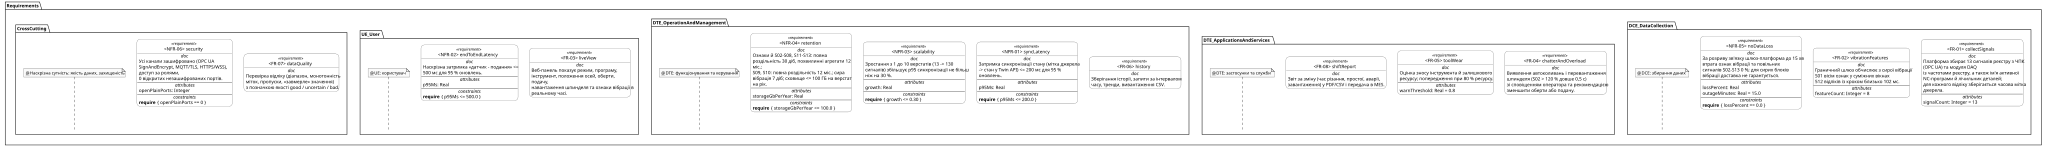

In [2]:
%viz --view=tree CncMachineTwin::Requirements

## Діаграма визначення блоків платформи (аналог BDD)

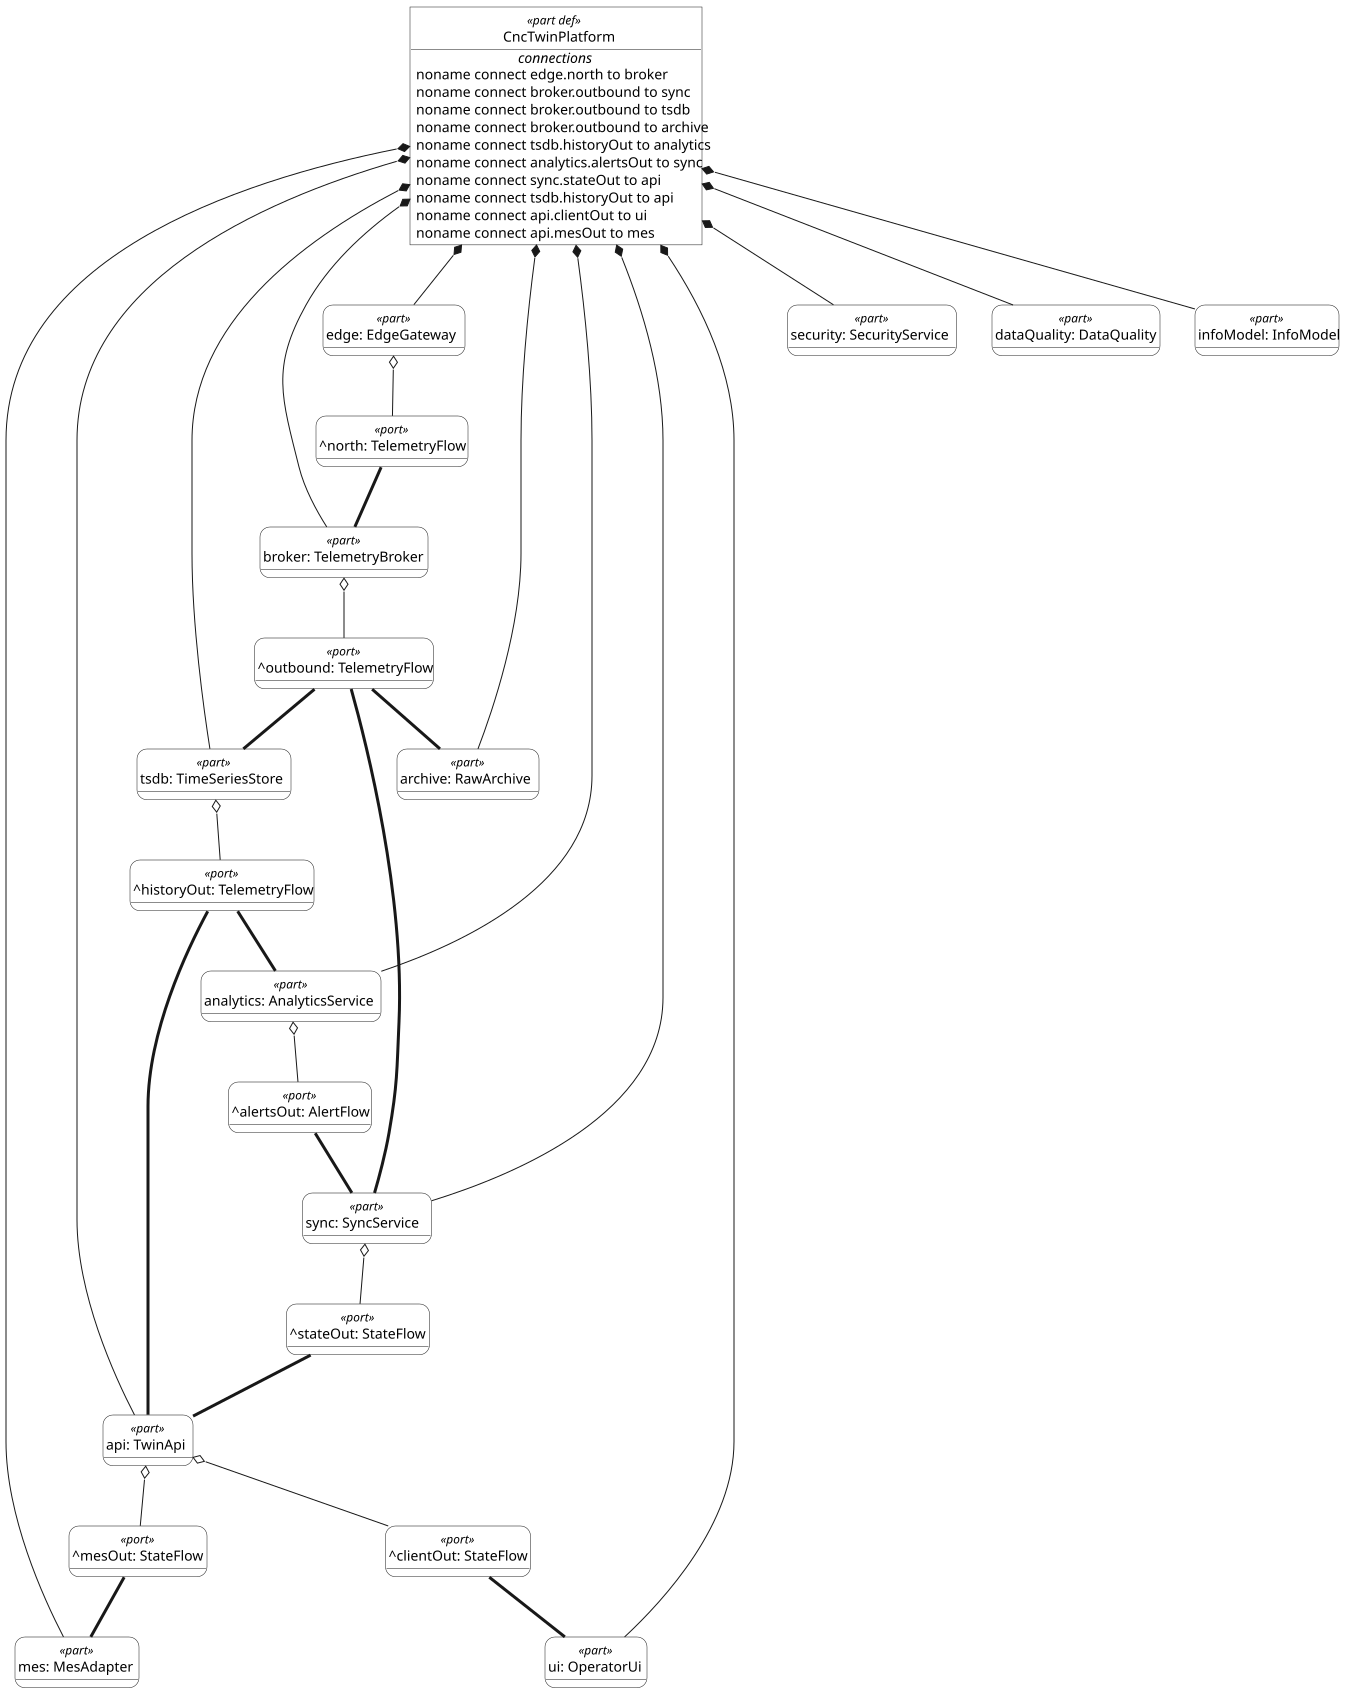

In [3]:
%viz --view=tree CncMachineTwin::Structure::CncTwinPlatform

## Внутрішня структура платформи (аналог IBD) — узгоджено з components.mmd

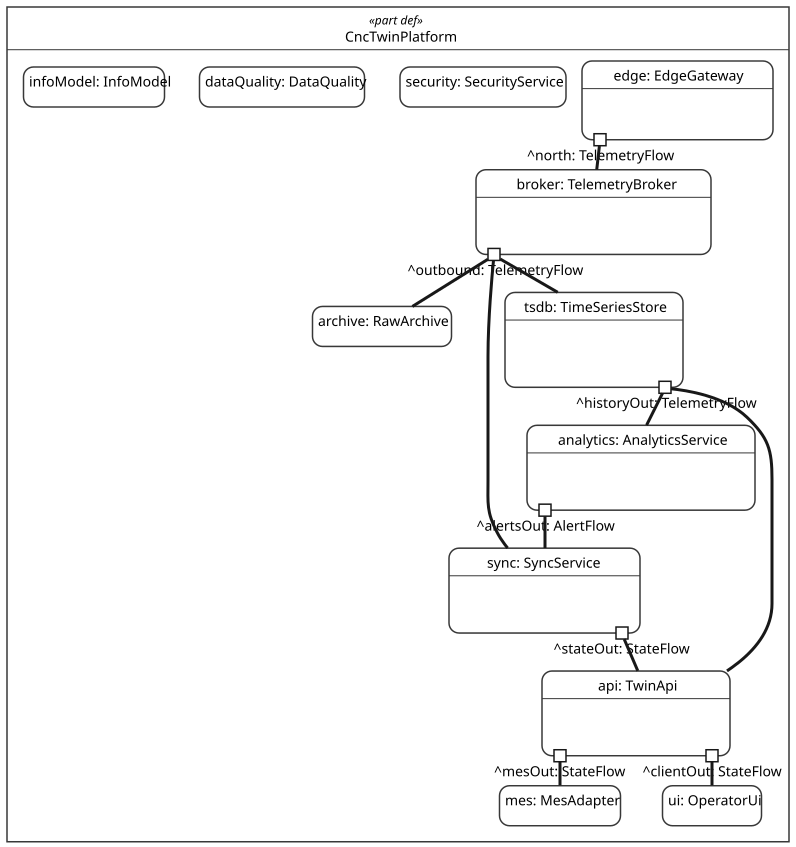

In [4]:
%viz --view=interconnection CncMachineTwin::Structure::CncTwinPlatform

## Внутрішня структура граничного шлюзу

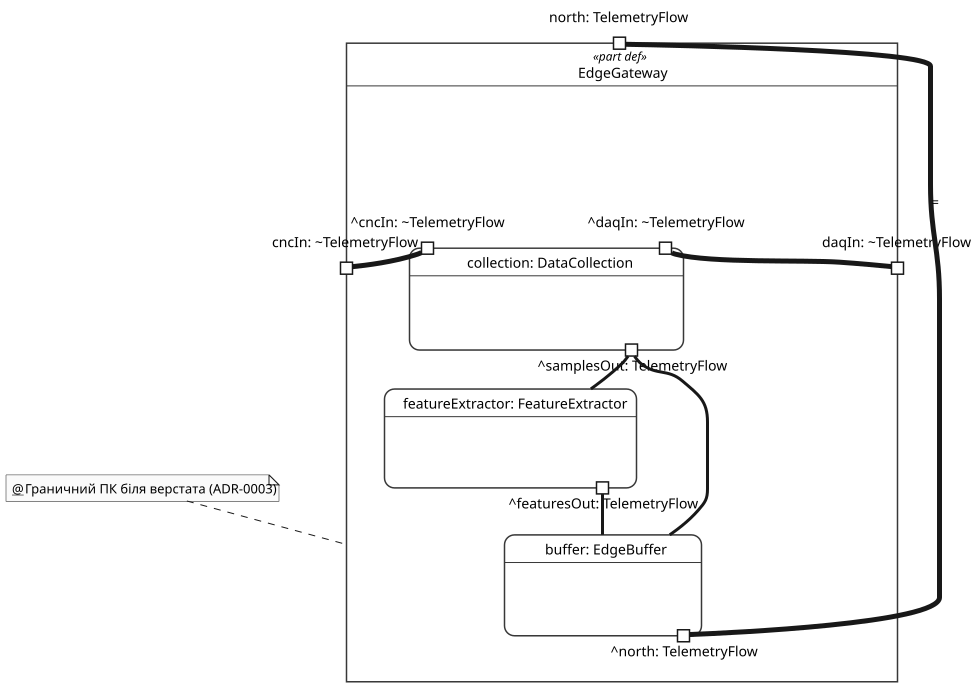

In [5]:
%viz --view=interconnection CncMachineTwin::Structure::EdgeGateway

## Поведінка: ключовий сценарій «надходження відліку — валідація — оновлення стану — сповіщення інтерфейсу»

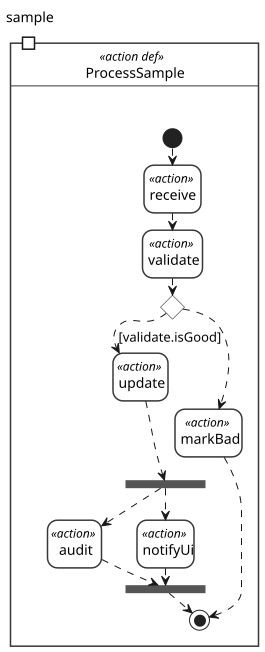

In [6]:
%viz --view=action CncMachineTwin::Behavior::ProcessSample

## Поведінка: стани верстата, які відстежує двійник (сигнал S11)

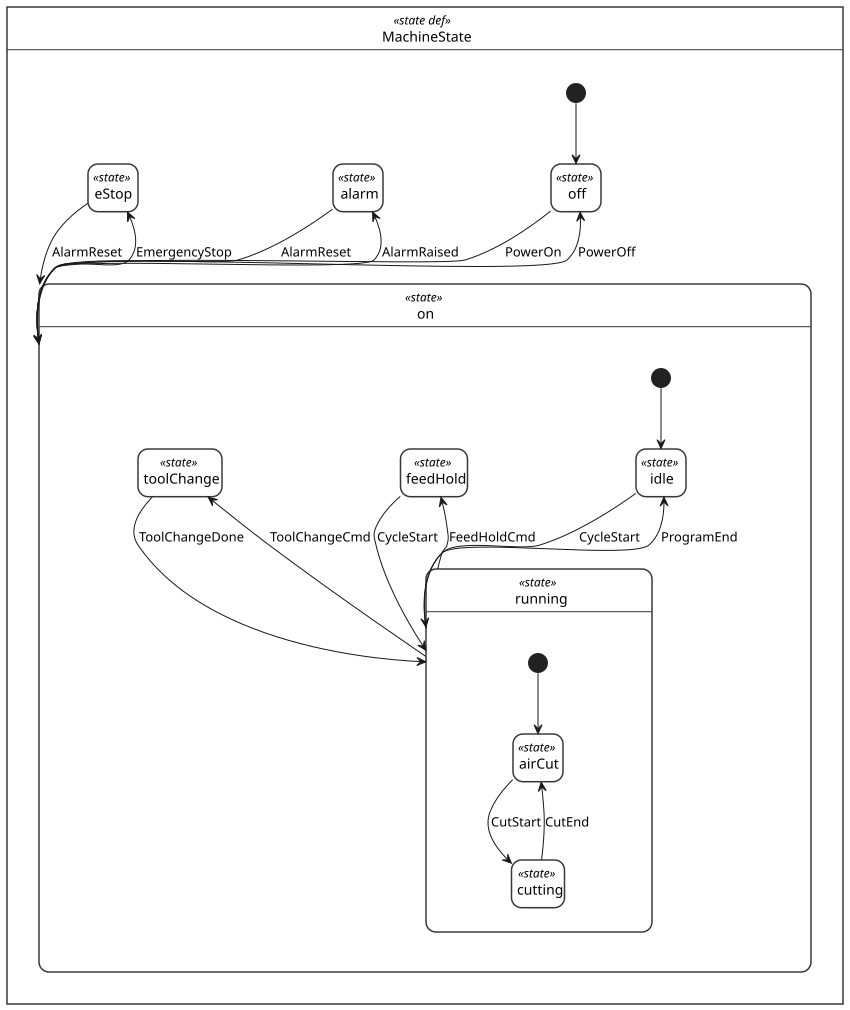

In [7]:
%viz --view=state CncMachineTwin::Behavior::MachineState

## Перелік зв’язків satisfy і verify

Матриця трасовності та покриття — `docs/traceability.md`, автоматична перевірка — `model/trace_check.py`.

In [8]:
%show CncMachineTwin::Traceability

Package Traceability (6ba04658-68c0-4fd7-92aa-c2a2ff83822e)
  [NamespaceImport] Package Requirements (5a1ae632-c13f-4a77-83c5-5424dddbd3f4)
  [NamespaceImport] Package Structure (1d2856fd-cb95-4e47-8bd2-048784e20bb1)
  [OwningMembership] SatisfyRequirementUsage (6ca2f10b-0eff-4282-959c-b26edf190c73)
  [OwningMembership] SatisfyRequirementUsage (20746954-8b48-4c7b-a476-5967465ff8c2)
  [OwningMembership] SatisfyRequirementUsage (b0dd9f09-badc-45ef-a65e-ce91d0aaffd1)
  [OwningMembership] SatisfyRequirementUsage (ba383b3b-4a5c-4ef2-b23b-c10ebf6c29a6)
  [OwningMembership] SatisfyRequirementUsage (0d28ac65-3c16-4acb-9252-e1e0d21630a7)
  [OwningMembership] SatisfyRequirementUsage (a35fad45-6862-4669-b26a-ef1d324b384b)
  [OwningMembership] SatisfyRequirementUsage (3e9987af-652c-4dee-b022-0d1f9c34fccd)
  [OwningMembership] SatisfyRequirementUsage (32cd6b91-175f-4b3f-bd00-cd73fd26e93f)
  [OwningMembership] SatisfyRequirementUsage (fcffda88-c8df-48b7-89b2-19279234b1ca)
  [OwningMembership] Satisf